# BÀI THỰC HÀNH TUẦN 7: MÔ HÌNH PERCEPTRON
- **Họ và tên**: Nguyễn Hải Anh  
- **MSSV**: 24001968  
- **Học phần**: Machine Learning


## Ví dụ 1: Xây dựng mô hình Perceptron thủ công trên dữ liệu 2D nhân tạo


Số lần cập nhật trọng số: 75
Bộ trọng số hội tụ w[-1]:
 [[ 13.97858527]
 [-15.02901929]
 [ 14.38743059]]


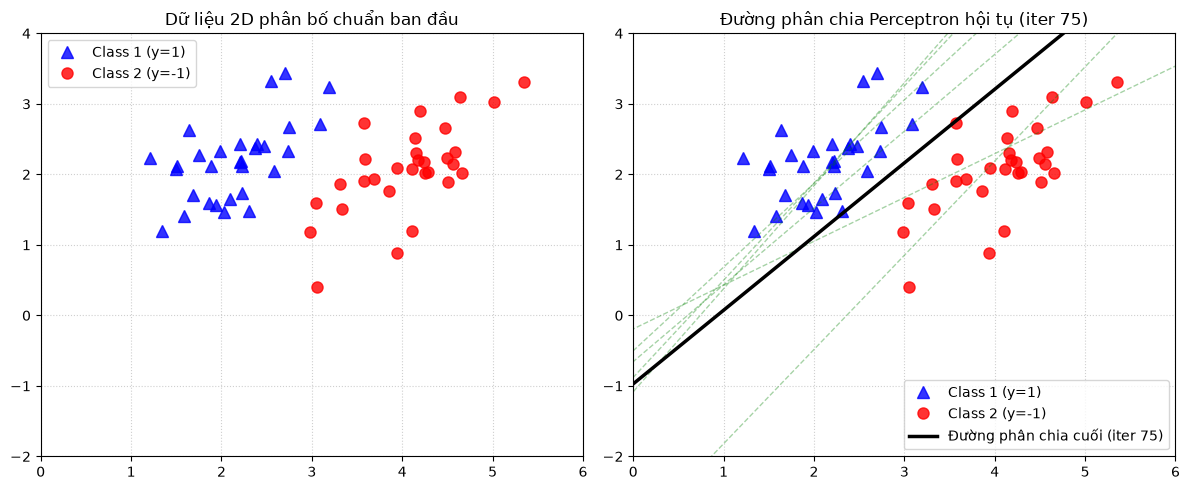

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Tạo tập dữ liệu ngẫu nhiên 2 chiều
np.random.seed(2)
means = [[2, 2], [4, 2]]
cov = [[.3, .2], [.2, .3]]
N = 30
X0 = np.random.multivariate_normal(means[0], cov, N).T
X1 = np.random.multivariate_normal(means[1], cov, N).T

X = np.concatenate((X0, X1), axis=1)
y = np.concatenate((np.ones((1, N)), -1 * np.ones((1, N))), axis=1)
# Bổ sung hàng x0 = 1 (Xbar)
X_bar = np.concatenate((np.ones((1, 2 * N)), X), axis=0)

# 2. Định nghĩa các hàm Perceptron
def h(w, x):
    return np.sign(np.dot(w.T, x))

def has_converged(X, y, w):
    return np.array_equal(h(w, X), y)

def perceptron(X, y, w_init, max_epochs=1000):
    w = [w_init]
    d, N_samples = X.shape
    mis_points = []
    best_w = w_init
    min_err = N_samples + 1
    
    for _ in range(max_epochs):
        mix_id = np.random.permutation(N_samples)
        for i in range(N_samples):
            xi = X[:, mix_id[i]].reshape(d, 1)
            yi = y[0, mix_id[i]]
            pred = h(w[-1], xi)[0, 0]
            if pred == 0:
                pred = 1
            if pred != yi:
                mis_points.append(mix_id[i])
                w_new = w[-1] + yi * xi
                w.append(w_new)
                err = np.sum(h(w_new, X) != y)
                if err < min_err:
                    min_err = err
                    best_w = w_new
        if has_converged(X, y, w[-1]):
            break
    if not has_converged(X, y, w[-1]):
        w.append(best_w)
    return (w, mis_points)

def draw_line(w, style='k-', lw=2, alpha=1.0, label=None):
    w0, w1, w2 = w[0, 0], w[1, 0], w[2, 0]
    if w2 != 0:
        x11, x12 = -100, 100
        return plt.plot([x11, x12], [-(w1 * x11 + w0) / w2, -(w1 * x12 + w0) / w2], style, lw=lw, alpha=alpha, label=label)
    else:
        x10 = -w0 / w1
        return plt.plot([x10, x10], [-100, 100], style, lw=lw, alpha=alpha, label=label)

# 3. Huấn luyện
d = X_bar.shape[0]
w_init = np.random.randn(d, 1)
(w_hist, m_pts) = perceptron(X_bar, y, w_init)
print("Số lần cập nhật trọng số:", len(w_hist) - 1)
print("Bộ trọng số hội tụ w[-1]:\n", w_hist[-1])

# 4. Hiển thị dữ liệu gốc và quá trình hội tụ của đường phân chia
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(X0[0, :], X0[1, :], 'b^', markersize=8, alpha=0.8, label='Class 1 (y=1)')
plt.plot(X1[0, :], X1[1, :], 'ro', markersize=8, alpha=0.8, label='Class 2 (y=-1)')
plt.axis([0, 6, -2, 4])
plt.title('Dữ liệu 2D phân bố chuẩn ban đầu')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(X0[0, :], X0[1, :], 'b^', markersize=8, alpha=0.8, label='Class 1 (y=1)')
plt.plot(X1[0, :], X1[1, :], 'ro', markersize=8, alpha=0.8, label='Class 2 (y=-1)')
# Vẽ một số đường phân chia trung gian (mờ)
step_indices = np.linspace(0, len(w_hist) - 2, min(6, len(w_hist) - 1), dtype=int)
for idx_s in step_indices:
    draw_line(w_hist[idx_s], style='g--', lw=1, alpha=0.35)
# Vẽ đường phân chia cuối cùng khi hội tụ
draw_line(w_hist[-1], style='k-', lw=2.5, alpha=1.0, label=f'Đường phân chia cuối (iter {len(w_hist)-1})')
plt.axis([0, 6, -2, 4])
plt.title(f'Đường phân chia Perceptron hội tụ (iter {len(w_hist)-1})')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


## Ví dụ 2: Phân loại dữ liệu sóng thủy âm Sonar (Perceptron vs Logistic vs Naïve Bayes)


Kích thước dữ liệu Sonar: (208, 61)
Phân bố nhãn lớp:
 60
M    111
R     97
Name: count, dtype: int64

--- BẢNG SO SÁNH CÁC MÔ HÌNH TRÊN TẬP DỮ LIỆU SONAR (TRAIN:TEST = 7:3) ---
              Mô hình  Accuracy  Precision (M=1)  Recall (M=1)  Thời gian chạy (s)
Perceptron (Thủ công)  0.761905         0.777778      0.800000            0.306887
  Logistic Regression  0.809524         0.810811      0.857143            0.005394
 Gaussian Naïve Bayes  0.777778         0.920000      0.657143            0.001063


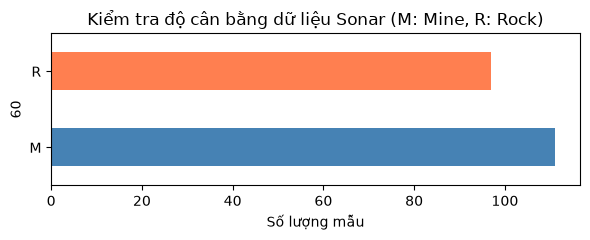

In [4]:
import time
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score

# 1. Đọc dữ liệu Sonar và kiểm tra cân bằng dữ liệu
main_df = pd.read_csv('sonar.all-data.csv', header=None)
print("Kích thước dữ liệu Sonar:", main_df.shape)
print("Phân bố nhãn lớp:\n", main_df[60].value_counts())

plt.figure(figsize=(6, 2.5))
main_df[60].value_counts().plot(kind='barh', color=['steelblue', 'coral'])
plt.title('Kiểm tra độ cân bằng dữ liệu Sonar (M: Mine, R: Rock)')
plt.xlabel('Số lượng mẫu')
plt.tight_layout()
plt.show()

# Đổi nhãn {'M': 1, 'R': -1} và bổ sung cột x0 = 1
y_df = main_df[60]
targets_label = {'M': 1, 'R': -1}
targets_df = np.array([targets_label[item] for item in y_df])

inputs_df = main_df.drop(60, axis=1)
x0 = np.ones((inputs_df.shape[0], 1))
X_sonar = np.concatenate((x0, inputs_df.values), axis=1)

# Chia Train:Test tỷ lệ 7:3
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_sonar, targets_df, test_size=0.30, random_state=42
)

# 2. Câu a & b: Huấn luyện và đánh giá Perceptron (sử dụng hàm ở Ví dụ 1)
t0 = time.perf_counter()
np.random.seed(42)
w_init_s = np.random.randn(X_train_s.shape[1], 1)
w_hist_s, _ = perceptron(X_train_s.T, y_train_s.reshape(1, -1), w_init_s, max_epochs=500)
w_final_s = w_hist_s[-1]

y_pred_perc = h(w_final_s, X_test_s.T).ravel()
y_pred_perc[y_pred_perc == 0] = 1
time_perc = time.perf_counter() - t0

# 3. Câu c: Thực nghiệm Logistic Regression & Gaussian Naïve Bayes (bỏ cột x0 cho sklearn)
X_train_s_sk = X_train_s[:, 1:]
X_test_s_sk = X_test_s[:, 1:]

t0 = time.perf_counter()
lr_sonar = LogisticRegression(max_iter=1000, random_state=42)
lr_sonar.fit(X_train_s_sk, y_train_s)
y_pred_lr = lr_sonar.predict(X_test_s_sk)
time_lr = time.perf_counter() - t0

t0 = time.perf_counter()
nb_sonar = GaussianNB()
nb_sonar.fit(X_train_s_sk, y_train_s)
y_pred_nb = nb_sonar.predict(X_test_s_sk)
time_nb = time.perf_counter() - t0

# Tổng hợp kết quả so sánh
df_sonar_comp = pd.DataFrame({
    'Mô hình': ['Perceptron (Thủ công)', 'Logistic Regression', 'Gaussian Naïve Bayes'],
    'Accuracy': [accuracy_score(y_test_s, y_pred_perc), accuracy_score(y_test_s, y_pred_lr), accuracy_score(y_test_s, y_pred_nb)],
    'Precision (M=1)': [precision_score(y_test_s, y_pred_perc, pos_label=1), precision_score(y_test_s, y_pred_lr, pos_label=1), precision_score(y_test_s, y_pred_nb, pos_label=1)],
    'Recall (M=1)': [recall_score(y_test_s, y_pred_perc, pos_label=1), recall_score(y_test_s, y_pred_lr, pos_label=1), recall_score(y_test_s, y_pred_nb, pos_label=1)],
    'Thời gian chạy (s)': [time_perc, time_lr, time_nb]
})
print("\n--- BẢNG SO SÁNH CÁC MÔ HÌNH TRÊN TẬP DỮ LIỆU SONAR (TRAIN:TEST = 7:3) ---")
print(df_sonar_comp.to_string(index=False))


### So sánh (Ví dụ 2 - câu c):
- **Độ chính xác**: Logistic Regression cao nhất (80.95%), GaussianNB (77.78%), Perceptron thủ công (76.19%).
- **Thời gian chạy**: GaussianNB nhanh nhất (~0.001s), Logistic Regression (~0.006s), Perceptron lâu nhất (~0.32s) do phải lặp đến ngưỡng max_epochs.


## Ví dụ 3: Phân loại dữ liệu Breast Cancer & Giảm chiều 2D (Sonar và Breast Cancer)


--- KẾT QUẢ PHÂN LOẠI TRÊN BREAST CANCER GỐC (30 CHIỀU) ---
Mô hình (Breast Cancer 30D)  Accuracy  Precision   Recall  Thời gian (s)
                 Perceptron  0.982456   0.981651 0.990741       0.001493
        Logistic Regression  0.982456   0.972973 1.000000       0.005398
       Gaussian Naïve Bayes  0.935673   0.944954 0.953704       0.001189

--- SO SÁNH PERCEPTRON VS LOGISTIC REGRESSION TRÊN DỮ LIỆU GIẢM CHIỀU 2D ---
   Bộ dữ liệu (2D)             Mô hình  Accuracy  Precision   Recall
        Sonar (2D)          Perceptron  0.634921   0.676471 0.657143
        Sonar (2D) Logistic Regression  0.682540   0.727273 0.685714
Breast Cancer (2D)          Perceptron  0.964912   0.963636 0.981481
Breast Cancer (2D) Logistic Regression  0.964912   0.955357 0.990741


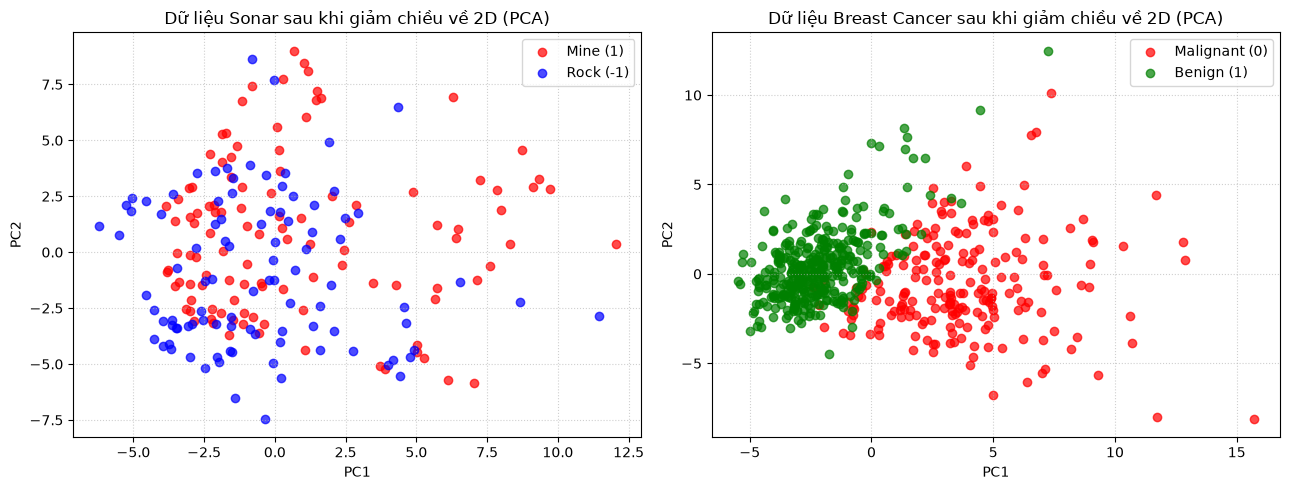

In [7]:
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Perceptron

# 1. Thực hiện tương tự Ví dụ 2 trên bộ dữ liệu Breast Cancer (30 chiều gốc)
cancer_data = datasets.load_breast_cancer()
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    cancer_data.data, cancer_data.target, test_size=0.3, random_state=109
)

scaler_c = StandardScaler()
X_train_c_sc = scaler_c.fit_transform(X_train_c)
X_test_c_sc = scaler_c.transform(X_test_c)

# Huấn luyện Perceptron, Logistic Regression và GaussianNB trên dữ liệu gốc (30D)
t0 = time.perf_counter()
perc_c_orig = Perceptron(random_state=42).fit(X_train_c_sc, y_train_c)
pred_c_perc_orig = perc_c_orig.predict(X_test_c_sc)
t_c_perc = time.perf_counter() - t0

t0 = time.perf_counter()
lr_c_orig = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_c_sc, y_train_c)
pred_c_lr_orig = lr_c_orig.predict(X_test_c_sc)
t_c_lr = time.perf_counter() - t0

t0 = time.perf_counter()
nb_c_orig = GaussianNB().fit(X_train_c_sc, y_train_c)
pred_c_nb_orig = nb_c_orig.predict(X_test_c_sc)
t_c_nb = time.perf_counter() - t0

df_cancer_orig = pd.DataFrame({
    'Mô hình (Breast Cancer 30D)': ['Perceptron', 'Logistic Regression', 'Gaussian Naïve Bayes'],
    'Accuracy': [accuracy_score(y_test_c, pred_c_perc_orig), accuracy_score(y_test_c, pred_c_lr_orig), accuracy_score(y_test_c, pred_c_nb_orig)],
    'Precision': [precision_score(y_test_c, pred_c_perc_orig), precision_score(y_test_c, pred_c_lr_orig), precision_score(y_test_c, pred_c_nb_orig)],
    'Recall': [recall_score(y_test_c, pred_c_perc_orig), recall_score(y_test_c, pred_c_lr_orig), recall_score(y_test_c, pred_c_nb_orig)],
    'Thời gian (s)': [t_c_perc, t_c_lr, t_c_nb]
})
print("--- KẾT QUẢ PHÂN LOẠI TRÊN BREAST CANCER GỐC (30 CHIỀU) ---")
print(df_cancer_orig.to_string(index=False))

# 2. Giảm số chiều về 02 chiều bằng PCA cho cả Sonar (Ví dụ 2) và Breast Cancer (Ví dụ 3)
scaler_s = StandardScaler()
X_train_s_sc = scaler_s.fit_transform(X_train_s_sk)
X_test_s_sc = scaler_s.transform(X_test_s_sk)

pca_s = PCA(n_components=2, random_state=42)
X_train_s_2d = pca_s.fit_transform(X_train_s_sc)
X_test_s_2d = pca_s.transform(X_test_s_sc)
X_all_s_2d = pca_s.transform(scaler_s.transform(inputs_df.values))

pca_c = PCA(n_components=2, random_state=42)
X_train_c_2d = pca_c.fit_transform(X_train_c_sc)
X_test_c_2d = pca_c.transform(X_test_c_sc)
X_all_c_2d = pca_c.transform(scaler_c.transform(cancer_data.data))

# 3. Trực quan hóa dữ liệu sau giảm chiều về 2D bằng 2 màu phân biệt
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_all_s_2d[targets_df == 1, 0], X_all_s_2d[targets_df == 1, 1], c='red', alpha=0.7, label='Mine (1)')
plt.scatter(X_all_s_2d[targets_df == -1, 0], X_all_s_2d[targets_df == -1, 1], c='blue', alpha=0.7, label='Rock (-1)')
plt.title('Dữ liệu Sonar sau khi giảm chiều về 2D (PCA)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.subplot(1, 2, 2)
plt.scatter(X_all_c_2d[cancer_data.target == 0, 0], X_all_c_2d[cancer_data.target == 0, 1], c='red', alpha=0.7, label='Malignant (0)')
plt.scatter(X_all_c_2d[cancer_data.target == 1, 0], X_all_c_2d[cancer_data.target == 1, 1], c='green', alpha=0.7, label='Benign (1)')
plt.title('Dữ liệu Breast Cancer sau khi giảm chiều về 2D (PCA)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 4. So sánh Hồi quy Logistic vs Perceptron trên cả 2 bộ dữ liệu (2D)
perc_s_2d = Perceptron(random_state=42).fit(X_train_s_2d, y_train_s)
pred_s_perc_2d = perc_s_2d.predict(X_test_s_2d)

lr_s_2d = LogisticRegression(random_state=42).fit(X_train_s_2d, y_train_s)
pred_s_lr_2d = lr_s_2d.predict(X_test_s_2d)

perc_c_2d = Perceptron(random_state=42).fit(X_train_c_2d, y_train_c)
pred_c_perc_2d = perc_c_2d.predict(X_test_c_2d)

lr_c_2d = LogisticRegression(random_state=42).fit(X_train_c_2d, y_train_c)
pred_c_lr_2d = lr_c_2d.predict(X_test_c_2d)

df_2d_comp = pd.DataFrame({
    'Bộ dữ liệu (2D)': ['Sonar (2D)', 'Sonar (2D)', 'Breast Cancer (2D)', 'Breast Cancer (2D)'],
    'Mô hình': ['Perceptron', 'Logistic Regression', 'Perceptron', 'Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test_s, pred_s_perc_2d), accuracy_score(y_test_s, pred_s_lr_2d),
        accuracy_score(y_test_c, pred_c_perc_2d), accuracy_score(y_test_c, pred_c_lr_2d)
    ],
    'Precision': [
        precision_score(y_test_s, pred_s_perc_2d, pos_label=1), precision_score(y_test_s, pred_s_lr_2d, pos_label=1),
        precision_score(y_test_c, pred_c_perc_2d), precision_score(y_test_c, pred_c_lr_2d)
    ],
    'Recall': [
        recall_score(y_test_s, pred_s_perc_2d, pos_label=1), recall_score(y_test_s, pred_s_lr_2d, pos_label=1),
        recall_score(y_test_c, pred_c_perc_2d), recall_score(y_test_c, pred_c_lr_2d)
    ]
})
print("\n--- SO SÁNH PERCEPTRON VS LOGISTIC REGRESSION TRÊN DỮ LIỆU GIẢM CHIỀU 2D ---")
print(df_2d_comp.to_string(index=False))


### So sánh (Ví dụ 3):
- **Breast Cancer**: Trước giảm chiều (30D) và sau giảm chiều (2D), Perceptron và Logistic Regression cho kết quả tương đương nhau (98.25% trên 30D; 96.49% trên 2D).
- **Sonar (2D)**: Logistic Regression (68.25%) tốt hơn Perceptron (63.49%) do dữ liệu 2D bị chồng lấn.


## Ví dụ 4: Dự đoán nguy cơ bệnh tim mạch vành (Framingham)


--- BẢNG HỆ SỐ MÔ HÌNH PERCEPTRON VÀ LOGISTIC REGRESSION (FRAMINGHAM) ---
     Thuộc tính  Hệ số Perceptron  Hệ số Logistic Reg
           male          2.148203            0.283994
            age          2.087296            0.567038
      education          5.770988           -0.014856
  currentSmoker          2.800226            0.070603
     cigsPerDay          3.889472            0.236018
         BPMeds          1.531337            0.046160
prevalentStroke          0.643110            0.107746
   prevalentHyp          1.748113            0.084262
       diabetes          1.531337            0.036641
        totChol          3.637366            0.138072
          sysBP          6.172026            0.363344
          diaBP          3.784103           -0.012080
            BMI          0.952083            0.010773
      heartRate          0.749642           -0.105202
        glucose          2.483729            0.151237
Hệ số chặn (Bias/Intercept): Perceptron = -9.0000 | Logistic =

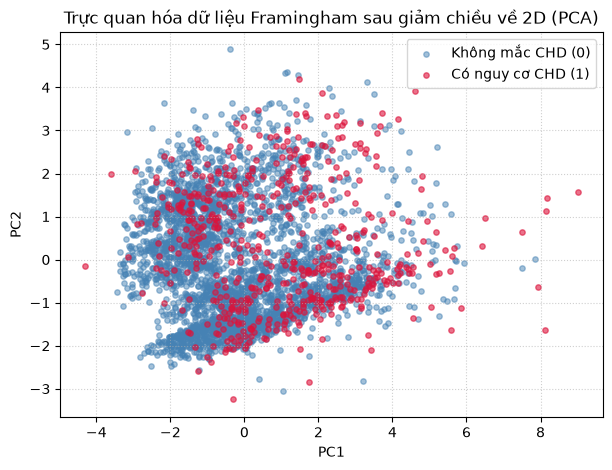

In [10]:
# 1. Đọc và tiền xử lý dữ liệu Framingham (giống tuần 3)
df_fram = pd.read_csv('framingham.csv').dropna(how='any', axis=0)
feature_names_f = df_fram.drop(columns=['TenYearCHD']).columns.tolist()
X_f = df_fram.drop(columns=['TenYearCHD']).values
y_f = df_fram['TenYearCHD'].values

# Chia tập Training : Validation = 7 : 3
X_tr_f, X_va_f, y_tr_f, y_va_f = train_test_split(X_f, y_f, test_size=0.3, random_state=42)

scaler_f = StandardScaler()
X_tr_f_sc = scaler_f.fit_transform(X_tr_f)
X_va_f_sc = scaler_f.transform(X_va_f)

# Câu 1: Giảm số chiều về 02 chiều bằng PCA và trực quan hóa
pca_f = PCA(n_components=2, random_state=42)
X_tr_f_2d = pca_f.fit_transform(X_tr_f_sc)
X_va_f_2d = pca_f.transform(X_va_f_sc)
X_all_f_2d = pca_f.transform(scaler_f.transform(X_f))

plt.figure(figsize=(7, 5))
plt.scatter(X_all_f_2d[y_f == 0, 0], X_all_f_2d[y_f == 0, 1], c='steelblue', alpha=0.5, s=15, label='Không mắc CHD (0)')
plt.scatter(X_all_f_2d[y_f == 1, 0], X_all_f_2d[y_f == 1, 1], c='crimson', alpha=0.6, s=15, label='Có nguy cơ CHD (1)')
plt.title('Trực quan hóa dữ liệu Framingham sau giảm chiều về 2D (PCA)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# Câu 2: Thực nghiệm trên dữ liệu gốc đã chuẩn hóa (15 chiều)
perc_f = Perceptron(random_state=42).fit(X_tr_f_sc, y_tr_f)
lr_f = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_f_sc, y_tr_f)
nb_f = GaussianNB().fit(X_tr_f_sc, y_tr_f)

# In bảng hệ số của Perceptron và Logistic Regression
df_coef_f = pd.DataFrame({
    'Thuộc tính': feature_names_f,
    'Hệ số Perceptron': perc_f.coef_[0],
    'Hệ số Logistic Reg': lr_f.coef_[0]
})
print("--- BẢNG HỆ SỐ MÔ HÌNH PERCEPTRON VÀ LOGISTIC REGRESSION (FRAMINGHAM) ---")
print(df_coef_f.to_string(index=False))
print(f"Hệ số chặn (Bias/Intercept): Perceptron = {perc_f.intercept_[0]:.4f} | Logistic = {lr_f.intercept_[0]:.4f}")

# Câu 3: Thực nghiệm lại câu 2 trên dữ liệu đã giảm chiều (2 chiều PCA)
perc_f2 = Perceptron(random_state=42).fit(X_tr_f_2d, y_tr_f)
lr_f2 = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_f_2d, y_tr_f)
nb_f2 = GaussianNB().fit(X_tr_f_2d, y_tr_f)

# Tổng hợp kết quả câu 2 và câu 3
fram_results = []
for space, models_list, X_va_use in [
    ('Dữ liệu gốc (15 chiều)', [('Perceptron', perc_f), ('Logistic Regression', lr_f), ('Gaussian Naïve Bayes', nb_f)], X_va_f_sc),
    ('Dữ liệu PCA (2 chiều)', [('Perceptron', perc_f2), ('Logistic Regression', lr_f2), ('Gaussian Naïve Bayes', nb_f2)], X_va_f_2d)
]:
    for m_name, mod in models_list:
        pr = mod.predict(X_va_use)
        fram_results.append({
            'Dữ liệu': space,
            'Mô hình': m_name,
            'Accuracy': accuracy_score(y_va_f, pr),
            'Precision': precision_score(y_va_f, pr, zero_division=0),
            'Recall': recall_score(y_va_f, pr, zero_division=0)
        })

df_fram_res = pd.DataFrame(fram_results)
print("\n--- SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH TRƯỚC VÀ SAU GIẢM CHIỀU (FRAMINGHAM) ---")
print(df_fram_res.to_string(index=False))


### Giải thích & Nhận xét (Ví dụ 4):
- **Ý nghĩa hệ số (2a, 2b)**: Sau chuẩn hóa, các hệ số dương lớn ở ge, sysBP, cigsPerDay, male, glucose làm tăng nguy cơ mắc CHD; hệ số âm ở heartRate, education (Logistic) làm giảm nhẹ xác suất lớp 1; Bias âm lớn ($-2.05$ và $-9.00$) phản ánh lớp 0 chiếm đa số.
- **So sánh gốc 15D (2c)**: Logistic Regression đạt Accuracy cao nhất (84.69%), GaussianNB (81.22%), Perceptron thấp nhất (71.56%) nhưng Recall cao nhất (41.38%).
- **Sau giảm chiều PCA 2D (3)**: Perceptron chịu ảnh hưởng nhiều nhất (Accuracy tăng lên 84.14% nhưng Recall tụt từ 41.38% về 0.00% do 2 lớp chồng lấn lệch về lớp 0). Logistic ổn định nhất (84.14%), GaussianNB tăng nhẹ Accuracy (83.50%) nhờ PCA triệt tiêu tương quan.


## Ví dụ 5: Phân tích dữ liệu giỏ hàng siêu thị Fresco (Analysis-Portfolio-Task-Data.csv)


In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Đọc và chuẩn hóa thông tin dạng số
df_fresco = pd.read_csv('Analysis-Portfolio-Task-Data.csv')
df_fresco_num = df_fresco.drop(columns=['CustomerID']).copy()

# Chuẩn hóa Gender: Male -> 1, Female -> 0
df_fresco_num['Gender'] = df_fresco_num['Gender'].map({'Male': 1, 'Female': 0})
# One-hot encoding Store Type (bỏ cột đầu Convenient Stores làm mốc tham chiếu tránh đa cộng tuyến)
df_fresco_num = pd.get_dummies(df_fresco_num, columns=['Store Type'], drop_first=True, dtype=int)

feat_cols_p = [c for c in df_fresco_num.columns if c != 'Shopping Basket']
X_p = df_fresco_num[feat_cols_p].values
y_p_reg = df_fresco_num['Shopping Basket'].values

# Chia 60 bản ghi đầu làm Training, 15 bản ghi cuối làm Validation
X_tr_p, X_va_p = X_p[:60], X_p[60:]
y_tr_p_reg, y_va_p_reg = y_p_reg[:60], y_p_reg[60:]

# --- Ý 1: Hồi quy tuyến tính dự đoán Shopping Basket ---
lin_reg = LinearRegression()
lin_reg.fit(X_tr_p, y_tr_p_reg)
y_pred_p_reg = lin_reg.predict(X_va_p)

print("=== Ý 1: KẾT QUẢ HỒI QUY TUYẾN TÍNH (DỰ BÁO SHOPPING BASKET) ===")
print(f"R2 Score: {r2_score(y_va_p_reg, y_pred_p_reg):.4f}")
print(f"RMSE    : {np.sqrt(mean_squared_error(y_va_p_reg, y_pred_p_reg)):.4f}")
print(f"MAE     : {mean_absolute_error(y_va_p_reg, y_pred_p_reg):.4f}")
print(f"Hệ số chặn (Intercept): {lin_reg.intercept_:.4f}")

df_lin_coef = pd.DataFrame({'Biến đầu vào': feat_cols_p, 'Hệ số hồi quy (w)': lin_reg.coef_})
print(df_lin_coef.to_string(index=False))

# --- Ý 2: Phân loại Shopping Basket > 50 (Lớp 1 vs Lớp 0) ---
y_tr_p_cls = np.where(y_tr_p_reg > 50, 1, 0)
y_va_p_cls = np.where(y_va_p_reg > 50, 1, 0)

# Chuẩn hóa đặc trưng bằng StandardScaler cho các mô hình phân loại tuyến tính
sc_p = StandardScaler()
X_tr_p_sc = sc_p.fit_transform(X_tr_p)
X_va_p_sc = sc_p.transform(X_va_p)

perc_p = Perceptron(random_state=42).fit(X_tr_p_sc, y_tr_p_cls)
lr_p = LogisticRegression(random_state=42).fit(X_tr_p_sc, y_tr_p_cls)
nb_p = GaussianNB().fit(X_tr_p_sc, y_tr_p_cls)

cls_res = []
for name_m, mod_m in [('a. Perceptron', perc_p), ('b. Logistic Regression', lr_p), ('c. Gaussian Naïve Bayes', nb_p)]:
    pr = mod_m.predict(X_va_p_sc)
    cls_res.append({
        'Mô hình': name_m,
        'Accuracy': accuracy_score(y_va_p_cls, pr),
        'Precision': precision_score(y_va_p_cls, pr, zero_division=0),
        'Recall': recall_score(y_va_p_cls, pr, zero_division=0)
    })

print("\n=== Ý 2: SO SÁNH PHÂN LOẠI (SHOPPING BASKET > 50) ===")
print(pd.DataFrame(cls_res).to_string(index=False))

df_cls_coef = pd.DataFrame({
    'Biến đầu vào': feat_cols_p,
    'Hệ số Perceptron': perc_p.coef_[0],
    'Hệ số Logistic Reg': lr_p.coef_[0],
    'NB Mean (Lớp 0)': nb_p.theta_[0],
    'NB Mean (Lớp 1)': nb_p.theta_[1]
})
print("\n--- BẢNG HỆ SỐ & THAM SỐ CÁC MÔ HÌNH PHÂN LOẠI ---")
print(df_cls_coef.to_string(index=False))
print(f"Bias (Intercept): Perceptron = {perc_p.intercept_[0]:.4f} | Logistic = {lr_p.intercept_[0]:.4f}")


=== Ý 1: KẾT QUẢ HỒI QUY TUYẾN TÍNH (DỰ BÁO SHOPPING BASKET) ===
R2 Score: 0.8359
RMSE    : 17.5289
MAE     : 13.0833
Hệ số chặn (Intercept): 8.4167
         Biến đầu vào  Hệ số hồi quy (w)
               Gender          -2.983398
                  Age           0.113449
       Value Products           0.964185
       Brand Products           0.987216
  Top Fresco Products           2.423241
    Store Type_Online          17.703245
Store Type_Superstore           6.504749

=== Ý 2: SO SÁNH PHÂN LOẠI (SHOPPING BASKET > 50) ===
                Mô hình  Accuracy  Precision  Recall
          a. Perceptron  1.000000        1.0     1.0
 b. Logistic Regression  1.000000        1.0     1.0
c. Gaussian Naïve Bayes  0.733333        1.0     0.5

--- BẢNG HỆ SỐ & THAM SỐ CÁC MÔ HÌNH PHÂN LOẠI ---
         Biến đầu vào  Hệ số Perceptron  Hệ số Logistic Reg  NB Mean (Lớp 0)  NB Mean (Lớp 1)
               Gender          1.000000            0.296783         0.040000        -0.028571
                

### Giải thích hệ số & So sánh (Ví dụ 5):
- **Ý 1 (Hồi quy tuyến tính)**: ^2 = 0.8359$,  = 13.08$. Các hệ số dương: Store Type_Online ($+17.70$), Store Type_Superstore ($+6.50$), Top Fresco Products ($+2.42$), Brand Products ($+0.99$), Value Products ($+0.96$), Age ($+0.11$) làm tăng giá trị giỏ hàng; Gender ($-2.98$) cho thấy nam chi tiêu thấp hơn nữ.
- **Ý 2 (Phân loại > 50)**:
  - *Perceptron (100%)* & *Logistic Regression (100%)*: Hệ số dương tập trung ở Brand Products, Value Products, Store Type_Online/Superstore, tách tuyến tính hoàn hảo 15 mẫu Validation.
  - *Gaussian Naïve Bayes (73.33%)*: Tham số trung bình chuẩn hóa (NB Mean) của các nhóm sản phẩm và Store Type_Online ở lớp 1 đều dương cao hơn lớp 0, nhưng mô hình kém hơn do biến nhị phân không theo phân phối chuẩn và các đặc trưng tương quan mạnh làm vi phạm giả định độc lập.
